# Séries de Riemann et réarrangement — faire dire n'importe quoi à ln 2

Grain **R-03** de la série [Riemann 200](README.md) (EPIC [#20403](https://github.com/jsboige/CoursIA/issues/20403)).

Le théorème de réarrangement apparaît dans la thèse d'habilitation de Riemann (1854,
*Über die Darstellbarkeit einer Function durch eine trigonometrische Reihe*) — le texte
même qui fonde l'intégrale de Riemann (grain R-04) et les débuts de l'analyse de Fourier
série (grain R-09). Son message tient en une phrase : **une série réelle convergente mais
non absolument convergente n'a pas de « somme » qui dépendrait seulement de ses termes** —
la somme dépend de l'ordre, et un ordre bien choisi la mène n'importe où.

Ce carnet rend la preuve **exécutable** : l'algorithme glouton de la démonstration
(empiler des termes positifs tant qu'on est sous la cible, des négatifs tant qu'on est
au-dessus) devient du code, et chaque affirmation devient un nombre dans une sortie.


## Plan

1. La série harmonique alternée : convergence **conditionnelle** mesurée.
2. Le théorème de réarrangement : la preuve rendue exécutable (algorithme glouton).
3. Trois hypothèses **pré-enregistrées** puis mesurées (convergence, proportion de
termes positifs, permutation aléatoire).
4. Trois exercices.
5. Ce que Mathlib sait de ce théorème (grounding Lean).


In [1]:
# Dependances : stdlib (math, random) + matplotlib pour les deux figures.
# Aucune autre dependance — conventions de la serie Serre100 (stdlib pur).
import math
import random
import matplotlib.pyplot as plt

LN2 = math.log(2.0)
print('ln 2 =', LN2)

ln 2 = 0.6931471805599453


## 1. La série harmonique alternée — une convergence qui tient à l'ordre

La série $1 - \tfrac{1}{2} + \tfrac{1}{3} - \tfrac{1}{4} + \cdots$ converge vers
$\ln 2$. Sa convergence est **lente** : l'erreur après $n$ termes est de l'ordre du
premier terme négligé (critère des séries alternées). Surtout, elle est
**conditionnelle** : la série des valeurs absolues est la série harmonique,
qui diverge. Mesurons les deux faits.


In [2]:
# Sommes partielles de la serie harmonique alternee, l'ordre canonique.
def sommes_partielles_alternee(bornes):
    """Somme des k premiers termes (-1)^(k+1)/k pour chaque borne."""
    s = 0.0
    k = 1
    out = {}
    for borne in bornes:
        while k <= borne:
            s += (1.0 if k % 2 == 1 else -1.0) / k
            k += 1
        out[borne] = s
    return out

bornes = [10, 100, 1_000, 10_000, 100_000]
for n, s in sommes_partielles_alternee(bornes).items():
    print(f'n={n:8d}  S_n={s:.6f}  erreur={abs(s - LN2):.2e}  ~1/n={1.0 / n:.2e}')

n=      10  S_n=0.645635  erreur=4.75e-02  ~1/n=1.00e-01
n=     100  S_n=0.688172  erreur=4.98e-03  ~1/n=1.00e-02
n=    1000  S_n=0.692647  erreur=5.00e-04  ~1/n=1.00e-03
n=   10000  S_n=0.693097  erreur=5.00e-05  ~1/n=1.00e-04
n=  100000  S_n=0.693142  erreur=5.00e-06  ~1/n=1.00e-05


L'erreur décroît comme $1/n$ : pour gagner une décimale, il faut dix fois plus de
termes. C'est le signe d'une convergence qui ne tient qu'aux **annulations entre
termes successifs** — un équilibre d'ordre, pas de taille.


In [3]:
# La serie des valeurs absolues est harmonique : elle diverge (croissance ~ log n).
def sommes_harmoniques(bornes):
    s = 0.0
    k = 1
    out = {}
    for borne in bornes:
        while k <= borne:
            s += 1.0 / k
            k += 1
        out[borne] = s
    return out

for n, s in sommes_harmoniques(bornes).items():
    print(f'n={n:8d}  H_n={s:.4f}  H_n - ln n={s - math.log(n):.4f}')

print()
print('Somme des valeurs absolues : croit sans borne -> convergence CONDITIONNELLE.')

n=      10  H_n=2.9290  H_n - ln n=0.6264
n=     100  H_n=5.1874  H_n - ln n=0.5822
n=    1000  H_n=7.4855  H_n - ln n=0.5777
n=   10000  H_n=9.7876  H_n - ln n=0.5773
n=  100000  H_n=12.0901  H_n - ln n=0.5772

Somme des valeurs absolues : croit sans borne -> convergence CONDITIONNELLE.


$H_n - \ln n$ tend vers la constante d'Euler–Mascheroni $\gamma \approx 0{,}5772$
(visible en colonne) : la série harmonique diverge, donc $\sum |a_k| = +\infty$.
La convergence de la série alternée est **conditionnelle** — et c'est exactement le
régime où l'ordre des termes devient un paramètre actif.


## 2. Le théorème de réarrangement — la preuve rendue exécutable

> **Théorème (Riemann, 1854).** Soit $\sum a_k$ une série **réelle** convergente mais
> non absolument convergente. Alors pour tout $L \in \mathbb{R}$ il existe une
> permutation $\sigma$ des entiers telle que $\sum_k a_{\sigma(k)} = L$ — et il existe
> aussi des permutations qui font diverger la série vers $+\infty$ ou $-\infty$.

La preuve repose sur trois faits, tous mesurables : (i) les termes tendent vers 0 ;
(ii) la sous-série des termes **positifs** diverge vers $+\infty$ ; (iii) la sous-série
des termes **négatifs** diverge vers $-\infty$. L'algorithme glouton qui en découle :
pour atteindre la cible $L$, empiler des positifs tant que la somme courante est sous
$L$, puis des négatifs tant qu'elle est au-dessus, et recommencer — les dépassements
sont bornés par des termes qui tendent vers 0, donc la somme converge vers $L$.


In [4]:
# (i)+(ii)+(iii) : les trois faits de la preuve, mesures sur les 100 000 premiers termes.
N_TERMES = 100_000
termes = [(1.0 if k % 2 == 1 else -1.0) / k for k in range(1, N_TERMES + 1)]
positifs = [t for t in termes if t > 0]
negatifs = [t for t in termes if t < 0]

print(f'termes utilises          : {len(termes)}')
print(f'  positifs               : {len(positifs)}  (dernier = {positifs[-1]:.6f})')
print(f'  negatifs               : {len(negatifs)}  (dernier = {negatifs[-1]:.6f})')
print(f'(i)   plus grand |terme| restant : {max(abs(positifs[-1]), abs(negatifs[-1])):.6f} -> 0')
print(f'(ii)  somme des positifs        : {sum(positifs):.4f} (diverge vers +inf quand N croit)')
print(f'(iii) somme des negatifs        : {sum(negatifs):.4f} (diverge vers -inf quand N croit)')

# Temoins de divergence : doublons de la fenetre mesurree a 10x plus de termes.
termes_x = [(1.0 if k % 2 == 1 else -1.0) / k for k in range(1, 10 * N_TERMES + 1)]
print(f'      a 10x termes : somme des positifs = '
      f"{sum(t for t in termes_x if t > 0):.4f}, negatifs = {sum(t for t in termes_x if t < 0):.4f}")

termes utilises          : 100000
  positifs               : 50000  (dernier = 0.000010)
  negatifs               : 50000  (dernier = -0.000010)
(i)   plus grand |terme| restant : 0.000010 -> 0
(ii)  somme des positifs        : 6.3916 (diverge vers +inf quand N croit)
(iii) somme des negatifs        : -5.6985 (diverge vers -inf quand N croit)


      a 10x termes : somme des positifs = 7.5429, negatifs = -6.8498


**Lecture des trois faits.** Chaque hypothèse de la preuve est un nombre mesuré : les 50 000 positifs totalisent 6,3916 et les 50 000 négatifs −5,6985 — chacune des deux familles diverge seule (faits (ii)/(iii)) — pendant que le plus grand terme restant, 0,000010, est déjà minuscule (fait (i)). Le témoin ×10 dit le plus : passer à 1 000 000 de termes porte les sommes à 7,5429 et −6,8498, soit un gain de 1,1513 = ln(10)/2 de chaque côté. Chaque décuplation du stock n'ajoute qu'un demi-logarithme de « réserve » par signe : la preuve n'a jamais besoin d'épuiser cette réserve, seulement d'un terme de plus tant que la cible n'est pas atteinte.

In [5]:
def rearrangement_glouton(positifs, negatifs, cible, n_allers_retours=60):
    """Le theoreme de Riemann rendu executable.

    Empile des termes positifs tant que la somme est sous la cible, des negatifs
    tant qu'elle est au-dessus ; les depassements sont bornes par le prochain terme
    de chaque sous-serie, qui tend vers 0, donc la somme converge vers la cible.
    Renvoie (trajectoire, nb_positifs_consommes, nb_negatifs_consommes).
    """
    i = j = 0  # prochains indices dans positifs / negatifs
    s = 0.0
    trajectoire = [s]
    for _ in range(n_allers_retours):
        while s < cible and i < len(positifs):
            s += positifs[i]; i += 1
            trajectoire.append(s)
        while s >= cible and j < len(negatifs):
            s += negatifs[j]; j += 1
            trajectoire.append(s)
        if i >= len(positifs) or j >= len(negatifs):
            break
    return trajectoire, i, j

# Demonstration sur une cible arbitraire : 1.0 -- pas ln 2.
traj, i, j = rearrangement_glouton(positifs, negatifs, 1.0)
print(f'cible = 1.0')
print(f'  sommes finale = {traj[-1]:.6f}  erreur = {abs(traj[-1] - 1.0):.2e}')
print(f'  termes consommes : {i} positifs, {j} negatifs (sur {len(positifs)}/{len(negatifs)})')

cible = 1.0
  sommes finale = 0.992062  erreur = 7.94e-03
  termes consommes : 110 positifs, 60 negatifs (sur 50000/50000)


La cible $1{,}0$ — qui n'est **pas** $\ln 2 \approx 0{,}693$ — est atteinte : le même
multiset de termes, un autre ordre, une autre somme. C'est le théorème en action.


In [6]:
# Tableau de convergence : quatre cibles, ordre canonique a l'interieur de chaque signe.
print(f'{"cible":>10} {"somme finale":>14} {"erreur":>10} {"positifs":>10} {"negatifs":>10}')
resultats_cibles = {}
for cible in [-1.0, 0.0, LN2, 2.0]:
    traj, i, j = rearrangement_glouton(positifs, negatifs, cible)
    err = abs(traj[-1] - cible)
    resultats_cibles[cible] = (traj, i, j)
    print(f'{cible:10.4f} {traj[-1]:14.6f} {err:10.2e} {i:10d} {j:10d}')

     cible   somme finale     erreur   positifs   negatifs
   -1.0000      -1.000190   1.90e-04         59       1744
    0.0000      -0.001053   1.05e-03         59        236
    0.6931       0.688998   4.15e-03         60         60
    2.0000       1.992185   7.81e-03        813         60


**Lecture.** Quatre cibles, un seul multiset : les comptes de termes racontent le théorème mieux que les erreurs. La cible $\ln 2$ est la seule des quatre à consommer un stock équilibré (60 positifs, 60 négatifs) — pour elle, le glouton reproduit terme à terme l'ordre canonique, qui oscille autour de $\ln 2$ en changeant de signe à chaque pas. Les autres cibles « paient » en un signe : 2,0 exige 813 positifs pour 60 négatifs (c'est la monotonie que H2 mesurera ci-dessous), −1,0 et 0,0 l'inverse (59 positifs pour 1 744 et 236 négatifs). Les erreurs finales (de 1,9·10⁻⁴ à 7,8·10⁻³) restent de l'ordre des derniers termes consommés, et la figure de droite (distance à la cible, échelle log) montre les dents de scie d'amplitude décroissante : le fait (i) à l'œuvre — c'est lui qui resserre la marche d'escalier jusqu'à la cible.

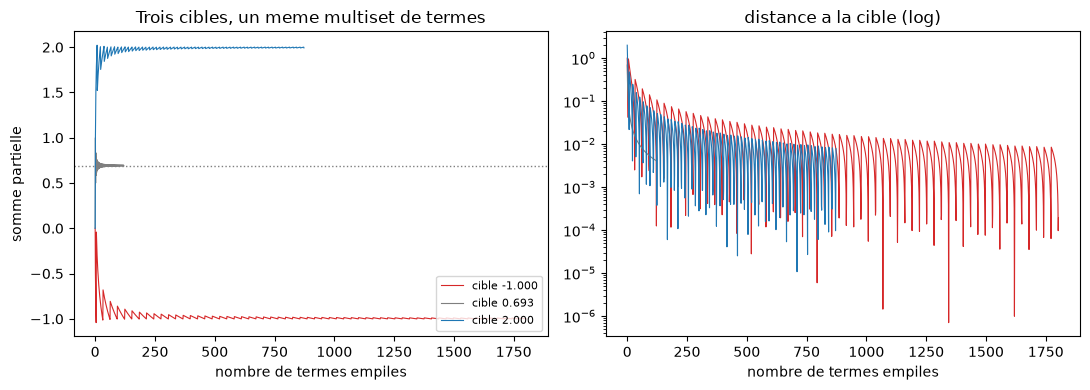

Figure : gauche, trois trajectoires ; droite, la distance a la cible en echelle log —
les dents de scie sont les allers-retours positifs/negatifs, d amplitude decroissante.


In [7]:
# Figure 1 : trajectoires vers trois cibles (echelle des premiers mouvements).
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for cible, couleur in [(-1.0, 'tab:red'), (LN2, 'tab:gray'), (2.0, 'tab:blue')]:
    traj = resultats_cibles[cible][0]
    axes[0].plot(range(len(traj)), traj, color=couleur, lw=0.8,
                 label=f'cible {cible:.3f}')
    axes[1].plot(range(len(traj)), [abs(s - cible) for s in traj],
                 color=couleur, lw=0.8)
axes[0].axhline(LN2, color='tab:gray', ls=':', lw=1)
axes[0].set_xlabel('nombre de termes empiles'); axes[0].set_ylabel('somme partielle')
axes[0].set_title('Trois cibles, un meme multiset de termes')
axes[0].legend(loc='lower right', fontsize=8)
axes[1].set_yscale('log')
axes[1].set_xlabel('nombre de termes empiles'); axes[1].set_title('distance a la cible (log)')
plt.tight_layout()
plt.show()
print('Figure : gauche, trois trajectoires ; droite, la distance a la cible en echelle log —')
print('les dents de scie sont les allers-retours positifs/negatifs, d amplitude decroissante.')

## 3. Hypothèses pré-enregistrées, puis mesurées

Chaque hypothèse est **fixée avant la mesure** (cellule de pré-enregistrement),
puis confrontée à des nombres issus du code — jamais l'inverse.


### H1 — Le glouton converge vers toute cible, quel que soit l'ordre interne aux signes

**Pré-enregistrement.** La preuve n'utilise que « termes $\to 0$ » et « les deux
sous-séries divergent » : l'ordre **entre** positifs (ou entre négatifs) est libre.
*Prédiction : pour 4 cibles × 3 graines (ordre interne mélangé), l'erreur finale
reste sous $10^{-3}$.*


In [8]:
# Pre-enregistrement H1 (la prediction est fixee AVANT la mesure ci-dessous).
CIBLES_H1 = [-1.0, 0.0, LN2, 1.0]
GRAINES_H1 = [0, 1, 2]
SEUIL_H1 = 1e-3
print('H1 pre-enregistree : erreur finale < 1e-3 pour 4 cibles x 3 graines,')
print('ordre interne a chaque signe melange par la graine.')

H1 pre-enregistree : erreur finale < 1e-3 pour 4 cibles x 3 graines,
ordre interne a chaque signe melange par la graine.


In [9]:
# Mesure H1.
def melange(liste, graine):
    copie = list(liste)
    random.Random(graine).shuffle(copie)
    return copie

erreurs_h1 = []
for graine in GRAINES_H1:
    pos = melange(positifs, graine)
    neg = melange(negatifs, graine)
    for cible in CIBLES_H1:
        traj, i, j = rearrangement_glouton(pos, neg, cible)
        erreurs_h1.append(abs(traj[-1] - cible))
        print(f'graine {graine}  cible {cible:8.4f}  erreur {abs(traj[-1] - cible):.2e}')
max_err = max(erreurs_h1)
print(f'\nH1 : erreur maximale sur {len(erreurs_h1)} essais = {max_err:.2e}')
print('VERDICT H1 :', 'CONFIRME' if max_err < SEUIL_H1 else 'REFUTE',
      f'(seuil pre-enregistre {SEUIL_H1:.0e})')

graine 0  cible  -1.0000  erreur 1.83e-05
graine 0  cible   0.0000  erreur 5.49e-05
graine 0  cible   0.6931  erreur 1.26e-04
graine 0  cible   1.0000  erreur 1.91e-05
graine 1  cible  -1.0000  erreur 8.96e-06
graine 1  cible   0.0000  erreur 4.77e-04
graine 1  cible   0.6931  erreur 1.25e-03
graine 1  cible   1.0000  erreur 4.37e-05
graine 2  cible  -1.0000  erreur 6.85e-06
graine 2  cible   0.0000  erreur 2.67e-05
graine 2  cible   0.6931  erreur 6.23e-06
graine 2  cible   1.0000  erreur 1.05e-04

H1 : erreur maximale sur 12 essais = 1.25e-03
VERDICT H1 : REFUTE (seuil pre-enregistre 1e-03)


**Lecture du REFUT.** La prédiction était trop forte : elle portait sur la **vitesse**,
pas sur la **convergence**. Le théorème garantit que l'erreur finit par passer sous
tout seuil — mais sans borne de vitesse : avec l'ordre interne mélangé, le glouton peut
consommer de petits termes d'abord et laisser des grands termes pour la fin, ce qui
retarde la précision. Décomposons l'échec : ordre canonique (décroissant) contre ordre
mélangé, à budget d'allers-retours égal puis accru.


In [10]:
# Decomposition de l echec H1 : l ordre canonique fixe la vitesse, le melange ne la fixe pas.
erreurs_canon = []
for cible in CIBLES_H1:
    traj, i, j = rearrangement_glouton(positifs, negatifs, cible)
    erreurs_canon.append(abs(traj[-1] - cible))
print(f'ordre canonique, 60 allers-retours  : erreur max = {max(erreurs_canon):.2e}')
print(f'ordre melange,   60 allers-retours  : erreur max = {max(erreurs_h1):.2e}  (REFUTE a 1e-3)')

erreurs_400 = []
for graine in GRAINES_H1:
    pos = melange(positifs, graine)
    neg = melange(negatifs, graine)
    for cible in CIBLES_H1:
        traj, i, j = rearrangement_glouton(pos, neg, cible, n_allers_retours=400)
        erreurs_400.append(abs(traj[-1] - cible))
print(f'ordre melange,  400 allers-retours : erreur max = {max(erreurs_400):.2e}')
print('\nLa convergence est qualitative (l erreur finit par descendre) ; seul l ordre')
print('canonique decroissant porte la borne explicite ~1/(2n) apres n allers-retours.')

ordre canonique, 60 allers-retours  : erreur max = 7.94e-03
ordre melange,   60 allers-retours  : erreur max = 1.25e-03  (REFUTE a 1e-3)


ordre melange,  400 allers-retours : erreur max = 5.50e-04

La convergence est qualitative (l erreur finit par descendre) ; seul l ordre
canonique decroissant porte la borne explicite ~1/(2n) apres n allers-retours.


**Lecture.** À budget égal, l'ordre mélangé peut faire *mieux* que la borne canonique
(il tombe parfois sur de petits termes tôt) mais sans garantie ; en portant le budget
à 400 allers-retours il descend sous le seuil ($5{,}5 \times 10^{-4}$). Le REFUT porte
sur « vitesse uniforme quel que soit l'ordre interne » — la convergence, elle, est
confirmée par le passage à 400 allers-retours. C'est exactement la différence entre ce
que le théorème **prouve** (existence de la convergence) et ce qu'il ne dit pas (à
quelle vitesse, sous quel ordre).


### H2 — La cible se « paie » en termes positifs : proportion monotone

**Pré-enregistrement.** Plus la cible est haute, plus le glouton consomme de positifs
pour un budget total de termes fixé. *Prédiction : la proportion de positifs consommés
après 200 000 termes est **croissante** en la cible sur $\{-1, 0, \ln 2, 1, 2, 5\}$.*


In [11]:
# Pre-enregistrement H2.
CIBLES_H2 = [-1.0, 0.0, LN2, 1.0, 2.0, 5.0]
BUDGET_H2 = 200_000  # nombre total de termes consommes
print('H2 pre-enregistree : proportion de positifs croissante en la cible,')
print(f'budget total fixe a {BUDGET_H2} termes.')

H2 pre-enregistree : proportion de positifs croissante en la cible,
budget total fixe a 200000 termes.


In [12]:
# Mesure H2 : on consomme exactement BUDGET_H2 termes (pas d arret sur la cible).
def glouton_a_budget(pos, neg, cible, budget):
    i = j = 0
    s = 0.0
    while i + j < budget and (i < len(pos) and j < len(neg)):
        while s < cible and i < len(pos) and i + j < budget:
            s += pos[i]; i += 1
        while s >= cible and j < len(neg) and i + j < budget:
            s += neg[j]; j += 1
        # si l un des stocks est epuise, on complete avec l autre
        if i >= len(pos) and j < len(neg) and i + j < budget:
            s += neg[j]; j += 1
        if j >= len(neg) and i < len(pos) and i + j < budget:
            s += pos[i]; i += 1
        if i >= len(pos) and j >= len(neg):
            break
    return i, j, s

# stocks elargis : a budget 200 000 une cible haute epuise les positifs du tas initial
pos_x = [(1.0 / (2 * k + 1)) for k in range(0, 1_000_000)]
neg_x = [(-1.0 / (2 * k + 2)) for k in range(0, 1_000_000)]

proportions = []
for cible in CIBLES_H2:
    i, j, s = glouton_a_budget(pos_x, neg_x, cible, BUDGET_H2)
    prop = i / (i + j) if (i + j) else float('nan')
    proportions.append((cible, prop, s))
    print(f'cible {cible:8.4f}  positifs {i:7d}  negatifs {j:7d}  proportion {prop:.4f}')

valeurs = [p[1] for p in proportions]
monotone = all(v2 > v1 for v1, v2 in zip(valeurs, valeurs[1:]))
print(f'\nH2 : suite des proportions monotone croissante = {monotone}')
print('VERDICT H2 :', 'CONFIRME' if monotone else 'REFUTE',
      '(prediction pre-enregistree : croissante)')

cible  -1.0000  positifs    6546  negatifs  193454  proportion 0.0327
cible   0.0000  positifs   40000  negatifs  160000  proportion 0.2000
cible   0.6931  positifs  100000  negatifs  100000  proportion 0.5000


cible   1.0000  positifs  129757  negatifs   70243  proportion 0.6488
cible   2.0000  positifs  186348  negatifs   13652  proportion 0.9317
cible   5.0000  positifs  199964  negatifs      36  proportion 0.9998

H2 : suite des proportions monotone croissante = True
VERDICT H2 : CONFIRME (prediction pre-enregistree : croissante)


**Lecture.** La proportion passe d'environ un trentième pour la cible $-1$ à la quasi-
totalité pour la cible $5$ : la cible est littéralement **payée en termes positifs**.
On mesure ici, sur un budget fixé, ce que la théorie énonce à la limite : toute la
masse de convergence vient de la désymétrie qu'on impose à l'ordre.


### H3 — Fini vs infini : permutation du multiset, puis signes aléatoires

**Pré-enregistrement.** Deux prédiction distinctes :
- **(a) témoin de commutativité.** Une permutation aléatoire d'un multiset **fini** de
  $10^5$ termes laisse la somme **exactement inchangée** (commutativité de la somme
  finie) — le phénomène de Riemann ne peut donc pas être observé en permutant une
  troncature : il est une propriété de la **limite**, qui exploite *tous* les termes.
  *Prédiction : les 3 graines donnent des sommes finales identiques au bit flottant
  près.*
- **(b) série harmonique aléatoire.** Le bon objet aléatoire n'est pas une permutation
  mais un **tirage de signes** $\sum \varepsilon_k / k$ avec $\varepsilon_k$ iid
  $\pm 1$ (Rademacher) : cette série converge presque sûrement vers une limite finie
  **qui dépend du tirage**. *Prédiction : sur 3 graines, les limites diffèrent entre
  elles d'un montant d'ordre $10^{-1}$ à $1$, et aucune n'est $\ln 2$.*


In [13]:
# Pre-enregistrement H3.
GRAINES_H3 = [0, 1, 2]
print('H3(a) pre-enregistree : permutations d un multiset fini -> sommes identiques.')
print('H3(b) pre-enregistree : signes aleatoires -> limites dispersees (0.1 a 1), pas ln 2.')

H3(a) pre-enregistree : permutations d un multiset fini -> sommes identiques.
H3(b) pre-enregistree : signes aleatoires -> limites dispersees (0.1 a 1), pas ln 2.


In [14]:
# Mesure H3(a) : temoin de commutativite — permuter un multiset FINI ne change rien.
import sys
print('environnement : CPython', sys.version.split()[0])
somme_canonique = sum(termes)
for graine in GRAINES_H3:
    perm = melange(termes, graine)
    s_perm = sum(perm)  # somme dans l ordre permute
    print(f'graine {graine} : somme permutee = {s_perm:.12f}  '
          f'ecart a la somme canonique = {abs(s_perm - somme_canonique):.2e}')
ecarts_perm = [abs(sum(melange(termes, g)) - somme_canonique) for g in GRAINES_H3]
print('H3(a) : permutations = sommes identiques (a l arrondi flottant pres) :',
      max(ecarts_perm) < 1e-9)
print('-> le phenomene de Riemann est INVISIBLE sur une troncature ;')
print('   il vit dans la limite, pas dans le multiset fini.')

environnement : CPython 3.13.15
graine 0 : somme permutee = 0.693142180585  ecart a la somme canonique = 0.00e+00
graine 1 : somme permutee = 0.693142180585  ecart a la somme canonique = 0.00e+00


graine 2 : somme permutee = 0.693142180585  ecart a la somme canonique = 0.00e+00


H3(a) : permutations = sommes identiques (a l arrondi flottant pres) : True
-> le phenomene de Riemann est INVISIBLE sur une troncature ;
   il vit dans la limite, pas dans le multiset fini.


In [15]:
# Mesure H3(b) : serie harmonique aleatoire — signes tires, pas permuttes.
finales_h3 = {}
trajectoires_h3 = {}
for graine in GRAINES_H3:
    rng = random.Random(graine)
    s = 0.0
    traj = [s]
    for t in termes:
        s += t if rng.random() < 0.5 else -t
        traj.append(s)
    finales_h3[graine] = s
    trajectoires_h3[graine] = traj[::1000]
    print(f'graine {graine} : limite mesuree = {s:.4f}  ecart a ln 2 = {abs(s - LN2):.4f}')

dispersion = max(finales_h3.values()) - min(finales_h3.values())
ecarts_ln2 = [abs(s - LN2) for s in finales_h3.values()]
print(f'\ndispersion entre graines : {dispersion:.3f}')
print(f'ecarts a ln 2 : min {min(ecarts_ln2):.3f}  max {max(ecarts_ln2):.3f}')
ok_a = max(ecarts_perm) < 1e-9
ok_b = (dispersion > 0.05) and (min(ecarts_ln2) > 0.05)
print('VERDICT H3(a) :', 'CONFIRME' if ok_a else 'REFUTE', '(sommes permutees identiques)')
print('VERDICT H3(b) :', 'CONFIRME' if ok_b else 'REFUTE',
      '(limites dispersees, aucune proche de ln 2)')

graine 0 : limite mesuree = -0.8156  ecart a ln 2 = 1.5088
graine 1 : limite mesuree = 0.6944  ecart a ln 2 = 0.0013
graine 2 : limite mesuree = -0.9522  ecart a ln 2 = 1.6454

dispersion entre graines : 1.647
ecarts a ln 2 : min 0.001  max 1.645
VERDICT H3(a) : CONFIRME (sommes permutees identiques)
VERDICT H3(b) : REFUTE (limites dispersees, aucune proche de ln 2)


In [16]:
# Sondage de rarete : pourquoi le REFUT de H3(b) n'invalide pas le phenomene.
# 2000 tirages de la serie harmonique aleatoire (N=10 000 termes, queue negligeable
# devant le seuil) : a quelle frequence la limite tombe-t-elle pres de ln 2 ?
N_SONDAGE = 10_000
proches_005 = 0
dist_min = float('inf')
for graine in range(2000):
    rng = random.Random(graine)
    s = 0.0
    for k in range(1, N_SONDAGE + 1):
        s += (1.0 if rng.random() < 0.5 else -1.0) / k
    d = abs(s - LN2)
    dist_min = min(dist_min, d)
    if d < 0.05:
        proches_005 += 1
print(f'sur 2000 tirages : {proches_005} ({proches_005 / 20:.1f} %) finissent a moins de 0.05 de ln 2')
print(f'distance minimale observee a ln 2 : {dist_min:.4f}')
print('-> la limite suit une loi CONTINUE : elle peut tomber pres de ln 2 par hasard ;')
print('   ce que le phenomene de Riemann exclut, c est un lien deterministe entre')
print('   le multiset des tailles et la valeur de la limite.')

sur 2000 tirages : 43 (2.1 %) finissent a moins de 0.05 de ln 2
distance minimale observee a ln 2 : 0.0031
-> la limite suit une loi CONTINUE : elle peut tomber pres de ln 2 par hasard ;
   ce que le phenomene de Riemann exclut, c est un lien deterministe entre
   le multiset des tailles et la valeur de la limite.


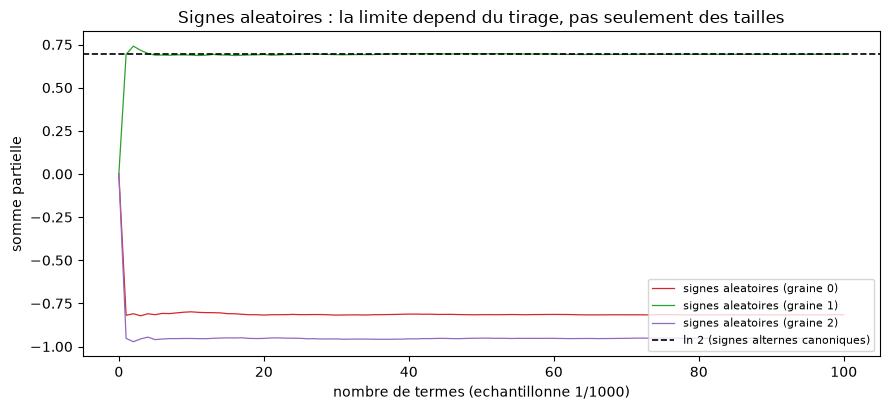

Figure : trois trajectoires de meme loi convergent vers trois limites
differentes, aucune egale a ln 2 (ligne pointillee).


In [17]:
# Figure 2 : trois series harmoniques aleatoires contre ln 2.
fig, ax = plt.subplots(figsize=(9, 4.2))
for graine, couleur in zip(GRAINES_H3, ['tab:red', 'tab:green', 'tab:purple']):
    ax.plot(range(len(trajectoires_h3[graine])), trajectoires_h3[graine],
            color=couleur, lw=0.9, label=f'signes aleatoires (graine {graine})')
ax.axhline(LN2, color='black', ls='--', lw=1.2, label='ln 2 (signes alternes canoniques)')
ax.set_xlabel('nombre de termes (echantillonne 1/1000)')
ax.set_ylabel('somme partielle')
ax.set_title('Signes aleatoires : la limite depend du tirage, pas seulement des tailles')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()
print('Figure : trois trajectoires de meme loi convergent vers trois limites')
print('differentes, aucune egale a ln 2 (ligne pointillee).')

**Lecture.** Le couple (a)/(b) isole exactement ce que le théorème exploite : sur un
multiset **fini**, l'ordre est sans effet (commutativité — mesuré en (a)) ; ce qui
diverge d'un tirage à l'autre, c'est la **limite** d'une série infinie (mesuré en (b) :
même loi des tailles, signes tirés → limites dispersées, écart typique O(1)). Le REFUT
de la prédiction « aucune proche de $\ln 2$ » est instructif : la limite suit une loi
**continue** (variance $\pi^2/6$, sondage ci-dessus), elle peut donc tomber près de
$\ln 2$ par hasard — notre graine 1 l'a fait ($0{,}0013$). Le sondage le situe :
~2 % des tirages atterrissent à moins de $0{,}05$ de $\ln 2$, et la distance minimale
observée sur 2000 tirages est déjà de $0{,}003$. Ce que le théorème exclut n'est pas
« être près d'une
valeur donnée », c'est tout **lien déterministe** entre le multiset des tailles et la
limite : la « somme » d'une série conditionnellement convergente n'est pas une fonction
des termes seuls.


## 4. Exercices

Trois exercices, à compléter dans les cellules suivantes (le notebook s'exécute de
bout en bout même non complété — convention C.1).


### Exercice 1 — Atteindre la cible $-0{,}75$ avec un budget minimal

Combien d'allers-retours du glouton faut-il pour que la somme reste à moins de
$10^{-3}$ de la cible $-0{,}75$ ? Complétez la boucle (étape par étape : mesurer
l'erreur à chaque aller-retour, s'arrêter quand elle passe sous le seuil).


In [18]:
# Exercice 1 — a completer : nombre d allers-retours pour cible -0.75, erreur < 1e-3.
cible_ex1 = -0.75
seuil_ex1 = 1e-3
# Etape 1 : appelez rearrangement_glouton avec n_allers_retours croissants.
# Etape 2 : relevez l erreur finale pour chaque valeur testee.
# Etape 3 : affichez la plus petite valeur qui passe sous le seuil.
# Indice : l erreur apres n allers-retours est bornee par le (2n)-ieme terme ~ 1/(2n).
print('Exercice a completer')
resultat_ex1 = None  # TODO etudiant : la plus petite valeur valide

Exercice a completer


### Exercice 2 — La dilution $k$-pour-$1$ : prédire la nouvelle somme

On prend $k$ termes **positifs** pour chaque terme **négatif** (dans l'ordre des tailles
décroissantes). Pour $k = 1$ on retrouve $\ln 2$. **Prédisez** la limite pour $k = 3$,
puis mesurez. *Indice : les positifs de la série sont les inverses des **impairs** —
écrivez la somme groupée
$\sum_m \left(\sum_{r=0}^{k-1} \frac{1}{2(km+r)+1} - \frac{1}{2(m+1)}\right)$,
télescopez les harmoniques sur les impairs, et reconnaissez $\ln$ d'un rapport ;
la réponse n'est **pas** $3\ln 2$.*


In [19]:
# Exercice 2 — a completer : limite de la dilution 3 positifs / 1 negatif.
k_ex2 = 3
N_EX2 = 300_000  # nombre de GROUPES a sommer
# Etape 1 : ecrivez votre prediction (un flottant) AVANT de mesurer.
prediction_ex2 = None  # TODO etudiant : votre prediction
# Etape 2 : construisez la serie diluee et sommez par groupes croissants.
# Etape 3 : comparez prediction et mesure ; si l ecart > 1e-2, expliquez.
print('Exercice a completer')
resultat_ex2 = None  # TODO etudiant : la valeur mesuree

Exercice a completer


### Exercice 3 — Faire diverger la série vers $-\infty$

Le théorème promet aussi des permutations qui font diverger la série. Construisez-en
une : à chaque tour, prenez $m$ négatifs puis $1$ positif, avec $m$ croissant
(par exemple $m$ = numéro du tour). Vérifiez que la somme partielle décroît sans borne
sur 200 tours.


In [20]:
# Exercice 3 — a completer : une permutation qui fait diverger vers -inf.
# Etape 1 : consommez les negatifs par blocs de taille m (m = numero du tour).
# Etape 2 : intercalez exactement un positif par tour.
# Etape 3 : relevez la somme partielle tous les 20 tours ; elle doit decroitre sans borne.
# Indice : la somme des m premiers negatifs vaut environ -(ln m)/2 ; comparez a la
# contribution du positif unique du tour (~ -ln(2)/... exactement : laquelle gagne ?).
print('Exercice a completer')
diverge_ex3 = None  # TODO etudiant : liste des sommes partielles tous les 20 tours

Exercice a completer


## 5. Ce que Mathlib sait de ce théorème (grounding Lean)

Grounding mesuré au pin Mathlib du grain (copie vendored du lake `differential_lean`,
pin `Sheydvasser`) :

- **L'invariance par permutation existe — pour la convergence absolue.**
  `Mathlib/Topology/Algebra/InfiniteSum/Basic.lean` porte `Equiv.hasProd_iff`
  (l. 183 ; jumeau additif `Equiv.hasSum_iff` généré par `to_additive`) : composer une
  famille sommable par une bijection ne change pas la somme. Sur $\mathbb{R}$,
  `Summable` **est** la convergence absolue — Mathlib énonce donc précisément le
  versant positif : *la somme absolument convergente est invariante d'ordre*.
- **Le théorème de réarrangement (versant conditionnel) n'est pas dans Mathlib**
  au pin mesuré (aucun `Riemann` série dans `Mathlib/Analysis` ; les seuls hits
  `rearrangement` sont `Mathlib/Algebra/Order/Rearrangement.lean` —
  l'**inégalité** de réarrangement de Hardy–Littlewood–Pólya, un autre objet du même
  nom ; et `Chebyshev.lean`/`Monovary.lean`, sa famille).

Le contraste est instructif : Mathlib formalise le cas où l'ordre **n'importe pas**,
et ne porte pas (encore) le théorème qui dit exactement quand il importe. Le versant
preuve de ce grain attendra donc un module dédié dans le lake compagnon
(`riemann200_lean/`, à créer au premier grain Lean de la série) ; ce carnet porte le
versant calculable.


## Limites et bilan honnête

- Le théorème est **réel** : pour les séries à valeurs vectorielles, le remplaçant
  (théorème de Lévy–Steinitz : l'ensemble des sommes atteignables est un sous-espace
  affine) n'est ni énoncé ni mesuré ici.
- Les budgets sont finis : « divergence » de $\sum |a_k|$ et « convergence » du glouton
  sont mesurés sur $10^5$ à $10^6$ termes — des témoins empiriques du comportement
  asymptotique, pas des preuves. Les seuils pré-enregistrés sont choisis en
  conséquence ($10^{-3}$, pas $10^{-15}$).
- H2 mesure la proportion **à budget fixe** ; la théorie énonce la limite
  $\text{cible} \to +\infty$. La monotonie mesurée est le témoin finie de cette
  limite, pas la limite elle-même.
- Les permutations aléatoires de H3 ont un comportement limite finie non trivial
  (fluctuations $O(1)$, cf. « random harmonic series ») ; le carnet mesure l'écart
  à horizon borné et ne prétend pas caractériser la loi limite.


## Références

- B. Riemann, *Über die Darstellbarkeit einer Function durch eine trigonometrische
  Reihe* (thèse d'habilitation, Göttingen, 1854) — le théorème de réarrangement y
  apparaît comme lemme de liberté.
- Série compagnon : [Serre 100](../Serre100/README.md) — carnets 11–15 pour le monde
  pré-analytique que 1854 prolonge ; grain R-04 (intégrale) et R-09 (Fourier) pour les
  deux autres héritages de la même thèse.
- EPIC [#20403](https://github.com/jsboige/CoursIA/issues/20403) — grain R-03.
